<table class="table table-bordered">
    <tr>
        <th style="text-align:center; vertical-align: middle; width:50%"><img src='https://www.np.edu.sg/_next/image?url=https%3A%2F%2Fassets.app.optical.gov.sg%2Fnp%2Fproduction%2Fpublished%2Fcollections%2Fpages%2F17c64bb4-8632-49e9-af16-047f7cabe99a%2Fab16008f-a6a0-466e-9193-e16e947261b0.png&w=640&q=75'"></th>
        <th style="text-align:center;"><h1>Deep Learning</h1><h2>Assignment 1 - Food Classification Model (Individual)</h2><h3>AY2026/27 Semester</h3></th>
    </tr>
</table>

In [7]:
# Import the Required Packages
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import keras
from keras import layers, models
from keras.applications import VGG16
from keras import regularizers
from keras.regularizers import l2
from keras.callbacks import EarlyStopping
import tensorflow as tf
print(tf.config.list_physical_devices('GPU'))



[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 1: Data Loading

In [9]:
img_size = 150
batchsize = 20

base_dir = "/home/alexm/projects/Datasets/"
train_dir = os.path.join(base_dir, 'train')
validation_dir = os.path.join(base_dir, 'validation')
test_dir = os.path.join(base_dir, 'test')

train = keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=(img_size, img_size),
    batch_size=batchsize,
    label_mode='categorical'
)

validation = keras.utils.image_dataset_from_directory(
    validation_dir,
    image_size=(img_size, img_size),
    batch_size=batchsize,
    label_mode='categorical'
)

# shuffle=False on the test set so predictions line up with labels in a fixed order
test = keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=(img_size, img_size),
    batch_size=batchsize,
    label_mode='categorical',
    shuffle=False
)


Found 7500 files belonging to 10 classes.


I0000 00:00:1785592947.236974    9441 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5518 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4070 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


Found 2000 files belonging to 10 classes.
Found 500 files belonging to 10 classes.


## Step 2:  Develop the Image Classification Models

### Model #1

In [10]:
# Build the Model
model = models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_size, img_size, 3)),
    layers.Conv2D(32, (3,3), activation = 'relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation = 'relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(128,(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation = 'relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(loss='categorical_crossentropy',
              optimizer='rmsprop',
              metrics=['accuracy'])

/home/alexm/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [11]:
# Train the Model
history = model.fit(train,
                    epochs = 10,
                    validation_data = validation)

Epoch 1/10


/home/alexm/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1785592955.356278   10011 service.cc:153] XLA service 0x726160033570 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1785592955.356326   10011 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4070 Laptop GPU, Compute Capability 8.9 (Driver: 13.3.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.24.0)
I0000 00:00:1785592955.424023   10011 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1785592955.609161   10011 cuda_dnn.cc:461] Loaded cuDNN version 92400
I0000 00:00:1785592955.626299   10011 dot_merger.cc:

  1/375 ━━━━━━━━━━━━━━━━━━━━ 1:03:14 10s/step - accuracy: 0.0500 - loss: 2.3183

I0000 00:00:1785592964.527444   10011 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


375/375 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.2135 - loss: 2.1466 - val_accuracy: 0.2720 - val_loss: 2.0386
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.3380 - loss: 1.8841 - val_accuracy: 0.3760 - val_loss: 1.8404
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.4245 - loss: 1.6609 - val_accuracy: 0.3680 - val_loss: 1.9165
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 15s 40ms/step - accuracy: 0.5169 - loss: 1.4090 - val_accuracy: 0.3925 - val_loss: 1.8798
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 17s 44ms/step - accuracy: 0.6187 - loss: 1.1133 - val_accuracy: 0.3600 - val_loss: 2.3343
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 13s 35ms/step - accuracy: 0.7373 - loss: 0.7931 - val_accuracy: 0.3745 - val_loss: 2.4552
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 33ms/step - accuracy: 0.8391 - loss: 0.4845 - val_accuracy: 0.3595 - val_loss: 3.2440
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - accuracy: 0.9032 - loss: 0.2907 - val_accuracy:

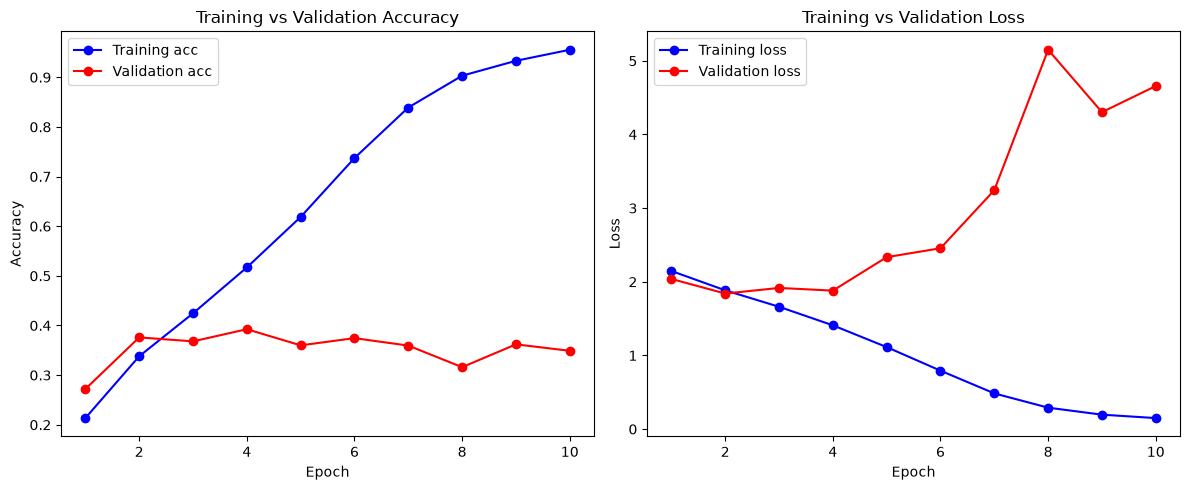

In [12]:
# Plot the Training and Validation Accuracy & Loss Scores

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs = range(1, len(acc) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs, acc, 'bo-', label='Training acc')
plt.plot(epochs, val_acc, 'ro-', label='Validation acc')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, loss, 'bo-', label='Training loss')
plt.plot(epochs, val_loss, 'ro-', label='Validation loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
# Save the Model
model.save('food_model_1.h5')

### Model #2

Epoch 1/20


/home/alexm/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/home/alexm/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1785593099.684163   10011 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_22779__.72


375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 67ms/step - accuracy: 0.3376 - loss: 2.5416 - val_accuracy: 0.4035 - val_loss: 1.8803
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 58ms/step - accuracy: 0.4235 - loss: 1.9258 - val_accuracy: 0.5295 - val_loss: 1.6910
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 55ms/step - accuracy: 0.4408 - loss: 1.8860 - val_accuracy: 0.4125 - val_loss: 1.9395
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 56ms/step - accuracy: 0.4395 - loss: 1.8855 - val_accuracy: 0.5035 - val_loss: 1.7665
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 55ms/step - accuracy: 0.4455 - loss: 1.8877 - val_accuracy: 0.5070 - val_loss: 1.7403
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 56ms/step - accuracy: 0.4473 - loss: 1.8766 - val_accuracy: 0.5180 - val_loss: 1.7122
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 44s 63ms/step - accuracy: 0.4477 - loss: 1.8692 - val_accuracy: 0.4975 - val_loss: 1.7565
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 86ms/step - accuracy: 0.4524 - loss: 1.8684 - val_accurac

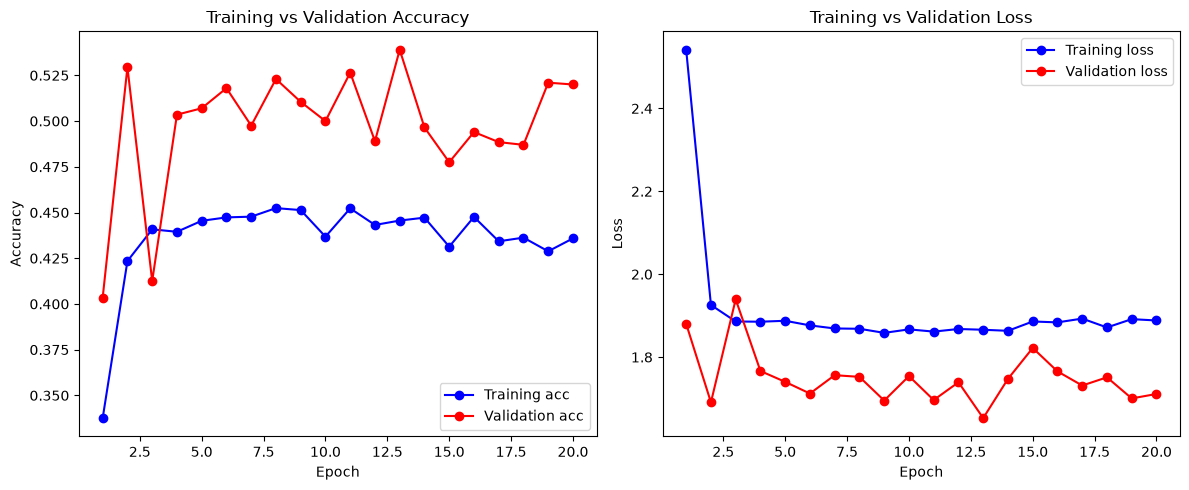

In [14]:
# Build the Model
conv_base = VGG16(weights='imagenet',
                   include_top=False,
                   input_shape=(img_size, img_size, 3))
conv_base.trainable = False

model2 = models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_size, img_size, 3)),
    conv_base,
    layers.Flatten(),
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.L2(0.01)),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model2.compile(loss='categorical_crossentropy',
               optimizer='rmsprop',
               metrics=['accuracy'])

history2 = model2.fit(
    train,
    epochs=20,
    validation_data=validation
)
# Plot the Training and Validation Accuracy & Loss Scores# Plot the Training and Validation Accuracy & Loss Scores

acc2 = history2.history['accuracy']
val_acc2 = history2.history['val_accuracy']
loss2 = history2.history['loss']
val_loss2 = history2.history['val_loss']

epochs2 = range(1, len(acc2) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs2, acc2, 'bo-', label='Training acc')
plt.plot(epochs2, val_acc2, 'ro-', label='Validation acc')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs2, loss2, 'bo-', label='Training loss')
plt.plot(epochs2, val_loss2, 'ro-', label='Validation loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [15]:
# Save the Model
model2.save('food_model_2.h5')

Model 3

Epoch 1/15


/home/alexm/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/home/alexm/miniconda3/envs/dl/lib/python3.11/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1785593599.997201   10013 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_63512__.70


375/375 ━━━━━━━━━━━━━━━━━━━━ 32s 66ms/step - accuracy: 0.3619 - loss: 1.9050 - val_accuracy: 0.5020 - val_loss: 1.4493
Epoch 2/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 58ms/step - accuracy: 0.5005 - loss: 1.4978 - val_accuracy: 0.5045 - val_loss: 1.4409
Epoch 3/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 59ms/step - accuracy: 0.5495 - loss: 1.3465 - val_accuracy: 0.5695 - val_loss: 1.3190
Epoch 4/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 24s 63ms/step - accuracy: 0.5869 - loss: 1.2296 - val_accuracy: 0.5695 - val_loss: 1.3117
Epoch 5/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 58ms/step - accuracy: 0.6171 - loss: 1.1614 - val_accuracy: 0.5665 - val_loss: 1.3078
Epoch 6/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 60ms/step - accuracy: 0.6252 - loss: 1.1194 - val_accuracy: 0.5925 - val_loss: 1.2620
Epoch 7/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 28s 75ms/step - accuracy: 0.6552 - loss: 1.0393 - val_accuracy: 0.5705 - val_loss: 1.3740
Epoch 8/15
375/375 ━━━━━━━━━━━━━━━━━━━━ 25s 67ms/step - accuracy: 0.6691 - loss: 0.9950 - val_accurac

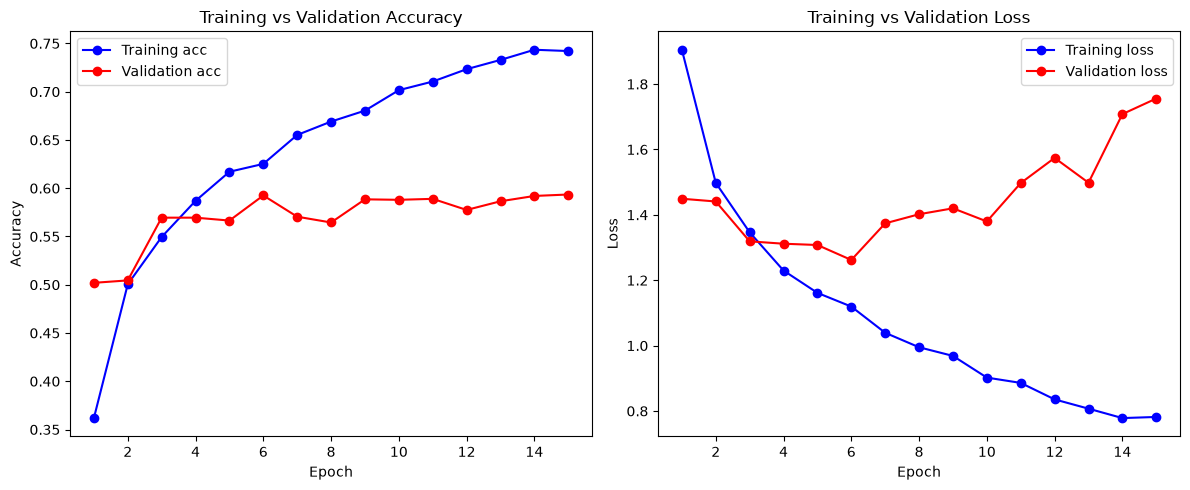

In [16]:
# MODEL 3
conv_base = VGG16(weights='imagenet',
                   include_top=False,
                   input_shape=(img_size, img_size, 3))
conv_base.trainable = False

model3 = models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_size, img_size, 3)),
    conv_base,
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])
model3.compile(loss='categorical_crossentropy',
               optimizer='rmsprop',
               metrics=['accuracy'])
# Train the Model
history3 = model3.fit(
    train,
    epochs=15,
    validation_data=validation
)
# Plot the Training and Validation Accuracy & Loss Scores# Plot the Training and Validation Accuracy & Loss Scores

acc3 = history3.history['accuracy']
val_acc3 = history3.history['val_accuracy']
loss3 = history3.history['loss']
val_loss3 = history3.history['val_loss']

epochs3 = range(1, len(acc3) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs3, acc3, 'bo-', label='Training acc')
plt.plot(epochs3, val_acc3, 'ro-', label='Validation acc')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs3, loss3, 'bo-', label='Training loss')
plt.plot(epochs3, val_loss3, 'ro-', label='Validation loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()



In [23]:
model3.save('food_model_3.h5')

Model 4

In [51]:
### WITH REGULARIZERS, DROPOUT, FREEZING LAYERS

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 59s 123ms/step - accuracy: 0.3244 - loss: 1.9724 - val_accuracy: 0.5440 - val_loss: 1.4545
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 113ms/step - accuracy: 0.5437 - loss: 1.4166 - val_accuracy: 0.6060 - val_loss: 1.2257
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 43s 114ms/step - accuracy: 0.6129 - loss: 1.2332 - val_accuracy: 0.6415 - val_loss: 1.1240
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 47s 126ms/step - accuracy: 0.6568 - loss: 1.0922 - val_accuracy: 0.6710 - val_loss: 1.0566
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 43s 115ms/step - accuracy: 0.6880 - loss: 1.0067 - val_accuracy: 0.6780 - val_loss: 1.0188
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 79s 106ms/step - accuracy: 0.7032 - loss: 0.9304 - val_accuracy: 0.6925 - val_loss: 0.9714
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 43s 115ms/step - accuracy: 0.7272 - loss: 0.8800 - val_accuracy: 0.6985 - val_loss: 0.9737
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 42s 111ms/step - accuracy: 0.7401 - loss: 0

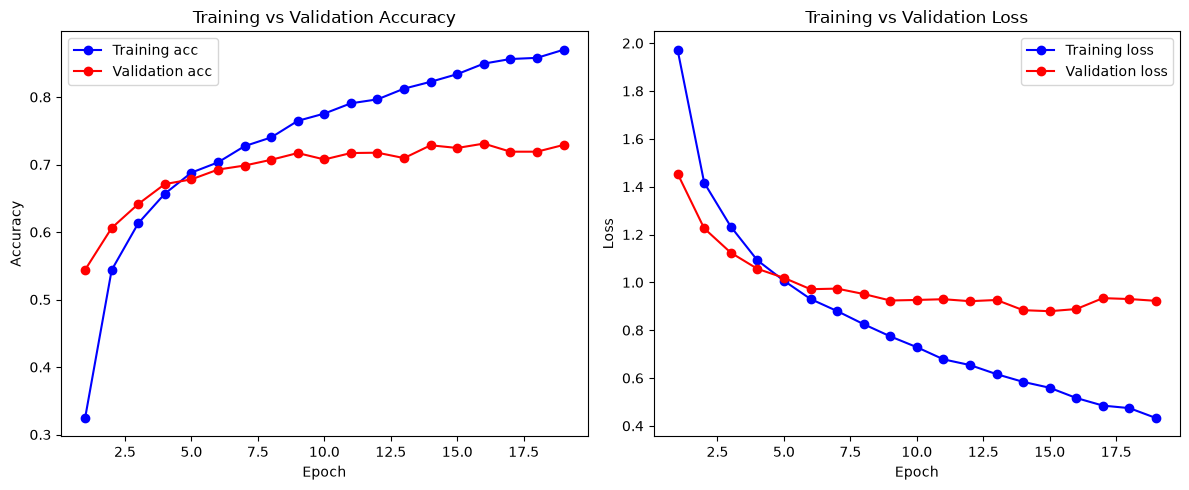

In [17]:
from keras.applications import VGG16
from keras import layers, models, regularizers
from keras.callbacks import EarlyStopping

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

conv_base = VGG16(weights='imagenet',
                   include_top=False,
                   input_shape=(img_size, img_size, 3))
conv_base.trainable = True

set_trainable = False
for layer in conv_base.layers:
    if layer.name == 'block5_conv1':
        set_trainable = True
    layer.trainable = set_trainable


model4 = models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_size, img_size, 3)),
    data_augmentation,
    conv_base,
    layers.Flatten(),
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.L2(0.0001)),
    layers.Dropout(0.3),
    layers.Dense(10, activation='softmax')
])

model4.compile(
    loss='categorical_crossentropy',
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # much lower LR than before
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

history4 = model4.fit(
    train,
    epochs=20,
    validation_data=validation,
    callbacks=[early_stop]
)

acc4 = history4.history['accuracy']
val_acc4 = history4.history['val_accuracy']
loss4 = history4.history['loss']
val_loss4 = history4.history['val_loss']

epochs4 = range(1, len(acc4) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs4, acc4, 'bo-', label='Training acc')
plt.plot(epochs4, val_acc4, 'ro-', label='Validation acc')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs4, loss4, 'bo-', label='Training loss')
plt.plot(epochs4, val_loss4, 'ro-', label='Validation loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [24]:
model4.save('food_model_4.h5')

Model 5

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 48s 116ms/step - accuracy: 0.2533 - loss: 2.1859 - val_accuracy: 0.4835 - val_loss: 1.6583
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 83s 118ms/step - accuracy: 0.4631 - loss: 1.6227 - val_accuracy: 0.5525 - val_loss: 1.3672
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 49s 130ms/step - accuracy: 0.5557 - loss: 1.3837 - val_accuracy: 0.6155 - val_loss: 1.2023
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 44s 117ms/step - accuracy: 0.6007 - loss: 1.2469 - val_accuracy: 0.6460 - val_loss: 1.1199
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 38s 100ms/step - accuracy: 0.6424 - loss: 1.1512 - val_accuracy: 0.6530 - val_loss: 1.0669
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 38s 101ms/step - accuracy: 0.6609 - loss: 1.0697 - val_accuracy: 0.6730 - val_loss: 1.0245
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 40s 106ms/step - accuracy: 0.6783 - loss: 1.0182 - val_accuracy: 0.6760 - val_loss: 0.9954
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 39s 103ms/step - accuracy: 0.7069 - loss: 0

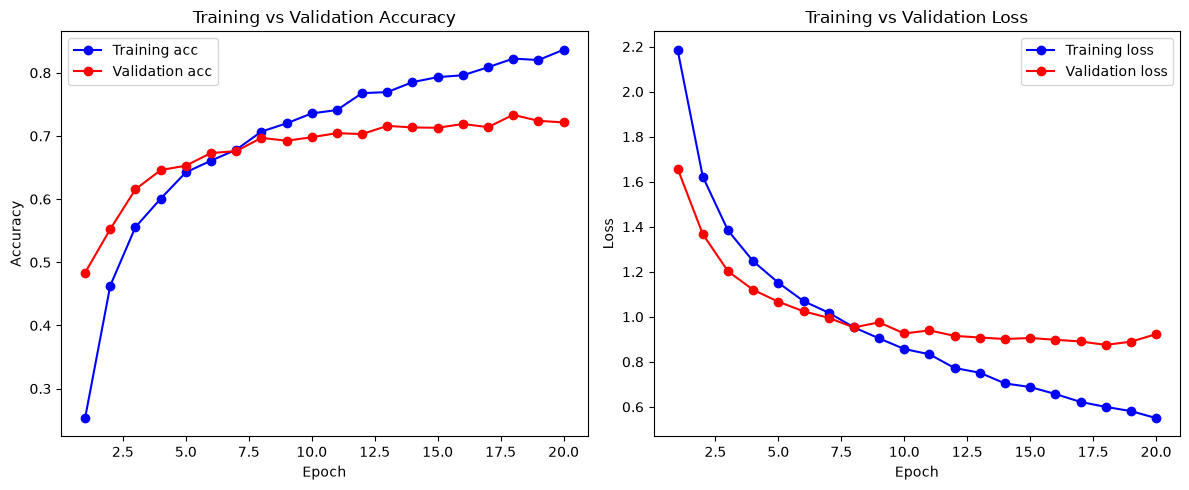

In [ ]:
#unfreezing last layer

data_augmentation = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

conv_base = VGG16(weights='imagenet',
                   include_top=False,
                   input_shape=(img_size, img_size, 3))
conv_base.trainable = True

set_trainable = False
for layer in conv_base.layers:
    if layer.name == 'block5_conv1':
        set_trainable = True
    layer.trainable = set_trainable


model5 = models.Sequential([
    layers.Rescaling(1./255, input_shape=(img_size, img_size, 3)),
    data_augmentation,
    conv_base,
    layers.Flatten(),
    layers.Dense(256, activation='relu', kernel_regularizer=regularizers.L2(0.0001)),
    layers.Dropout(0.5),
    layers.Dense(10, activation='softmax')
])

model5.compile(
    loss='categorical_crossentropy',
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  
    metrics=['accuracy']
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=4,
    restore_best_weights=True
)

history5 = model5.fit(
    train,
    epochs=20,
    validation_data=validation,
    callbacks=[early_stop]
)

acc5 = history5.history['accuracy']
val_acc5 = history5.history['val_accuracy']
loss5 = history5.history['loss']
val_loss5 = history5.history['val_loss']

epochs5 = range(1, len(acc5) + 1)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs5, acc5, 'bo-', label='Training acc')
plt.plot(epochs5, val_acc5, 'ro-', label='Validation acc')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs5, loss5, 'bo-', label='Training loss')
plt.plot(epochs5, val_loss5, 'ro-', label='Validation loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


In [19]:
model5.save('food_model_finetuned.h5')

## Step 3 – Evaluate the Developed Models using Testing Images

In [20]:
# Model #1
model1_loaded = keras.models.load_model('food_model_1.h5')
test_loss1, test_acc1 = model1_loaded.evaluate(test)
print('Model 1 - Test Loss:', test_loss1, ' Test Accuracy:', test_acc1)


25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 18ms/step - accuracy: 0.3380 - loss: 4.7926
Model 1 - Test Loss: 4.792608737945557  Test Accuracy: 0.33799999952316284


In [21]:
# Model #2
model2_loaded = keras.models.load_model('food_model_2.h5')
test_loss2, test_acc2 = model2_loaded.evaluate(test)
print('Model 3 - Test Loss:', test_loss2, ' Test Accuracy:', test_acc2)

25/25 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - accuracy: 0.5040 - loss: 1.7231
Model 3 - Test Loss: 1.7230563163757324  Test Accuracy: 0.5040000081062317


In [25]:
# Model #3
model3_loaded = keras.models.load_model('food_model_3.h5')  # match whatever filename you saved Model 3 as
test_loss3, test_acc3 = model3_loaded.evaluate(test)
print('Model 3 - Test Loss:', test_loss3, ' Test Accuracy:', test_acc3)

25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - accuracy: 0.5940 - loss: 1.8064
Model 3 - Test Loss: 1.8063722848892212  Test Accuracy: 0.593999981880188


In [26]:
# Model #4
model4_loaded = keras.models.load_model('food_model_4.h5')  # match whatever filename you saved Model 4 as
test_loss4, test_acc4 = model4_loaded.evaluate(test)
print('Model 4 - Test Loss:', test_loss4, ' Test Accuracy:', test_acc4)

25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - accuracy: 0.7300 - loss: 0.9349
Model 4 - Test Loss: 0.9348931908607483  Test Accuracy: 0.7300000190734863


In [27]:
# Model #5
model5_loaded = keras.models.load_model('food_model_finetuned.h5')
test_loss5, test_acc5 = model5_loaded.evaluate(test)
print('Model 5 - Test Loss:', test_loss5, ' Test Accuracy:', test_acc5)

25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 69ms/step - accuracy: 0.7340 - loss: 0.9064
Model 5 - Test Loss: 0.9064072966575623  Test Accuracy: 0.734000027179718


In [28]:
# Save the best model
results = {
    'Model 1': (model1_loaded, test_acc1),
    'Model 2': (model2_loaded, test_acc2),
    'Model 3': (model3_loaded, test_acc3),
    'Model 4': (model4_loaded, test_acc4),
    'Model 5': (model5_loaded, test_acc5),
}

best_name, (best_model, best_acc) = max(results.items(), key=lambda item: item[1][1])
print(f'Best model: {best_name} with test accuracy {best_acc:.4f}')

best_model.save('food_model_best.h5')

Best model: Model 5 with test accuracy 0.7340


25/25 ━━━━━━━━━━━━━━━━━━━━ 4s 52ms/step


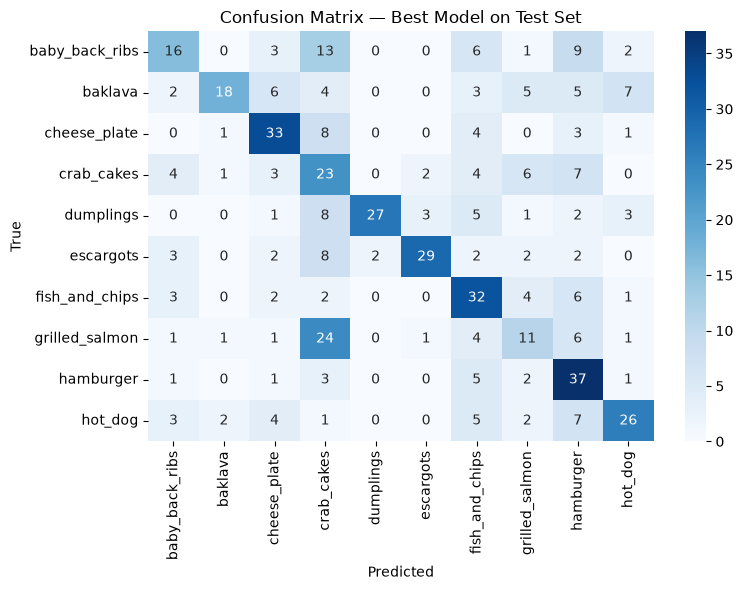

                precision    recall  f1-score   support

baby_back_ribs       0.48      0.32      0.39        50
       baklava       0.78      0.36      0.49        50
  cheese_plate       0.59      0.66      0.62        50
    crab_cakes       0.24      0.46      0.32        50
     dumplings       0.93      0.54      0.68        50
     escargots       0.83      0.58      0.68        50
fish_and_chips       0.46      0.64      0.53        50
grilled_salmon       0.32      0.22      0.26        50
     hamburger       0.44      0.74      0.55        50
       hot_dog       0.62      0.52      0.57        50

      accuracy                           0.50       500
     macro avg       0.57      0.50      0.51       500
  weighted avg       0.57      0.50      0.51       500

25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - accuracy: 0.7340 - loss: 0.9064


In [29]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

class_names = test.class_names

y_true = np.concatenate([y for x, y in test], axis=0)
y_true_labels = np.argmax(y_true, axis=1)

y_pred_probs = model2.predict(test)
y_pred_labels = np.argmax(y_pred_probs, axis=1)

cm = confusion_matrix(y_true_labels, y_pred_labels)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix — Best Model on Test Set')
plt.tight_layout()
plt.show()

print(classification_report(y_true_labels, y_pred_labels, target_names=class_names))
test_loss, test_acc = best_model.evaluate(test)

## Step 4  – Use the best model to make prediction

In [ ]:
# Load the model
model_ = keras.models.load_model('food_model_best.h5')

In [ ]:
# Load the food list (in alphabetical order)
with open(r"C:\Users\laksh\OneDrive\sem 1\idk\Desktop\DEEP LEARNING\ASSIGNMENT\Food_list\lakshya.txt", 'r') as f: # the .txt file which contains a list of food assigned to you
    x = f.readlines()
food_list =[]
for item in x:
    food_list.append(item.strip('\n'))
food_list = sorted(food_list) # food_list needs to be sorted alphabetically before feed into prediction() function
print(food_list)

['baby_back_ribs', 'baklava', 'cheese_plate', 'crab_cakes', 'dumplings', 'escargots', 'fish_and_chips', 'grilled_salmon', 'hamburger', 'hot_dog']


In [ ]:
# Define some related functions for image process and model prediction
from keras.preprocessing.image import load_img, img_to_array
def image_process(img):
    image = load_img(img, target_size =(img_size, img_size))
    image_array = img_to_array(image)
    return image_array

import pandas as pd
def prediction(model, img_array, items_l):
    prob = model.predict(img_array.reshape(1,img_size,img_size,3))
    pro_df = pd.DataFrame(prob, columns = items_l)
    result = items_l[np.argmax(prob)]
    return pro_df, result

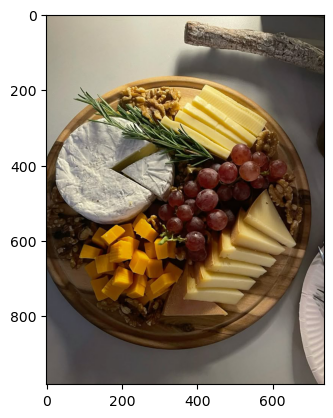

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
The prediction is:  grilled_salmon 

    baby_back_ribs   baklava  cheese_plate  crab_cakes  dumplings  escargots  \
0        0.166808  0.005345      0.099159    0.004161   0.000595   0.007143   

   fish_and_chips  grilled_salmon  hamburger   hot_dog  
0        0.004135        0.701833   0.010402  0.000417  


In [ ]:
# Make prediction for the image you downloaded from internet
import matplotlib.pyplot as plt
img = r"C:\Users\laksh\OneDrive\sem 1\idk\Desktop\DEEP LEARNING\ASSIGNMENT\charcuterie board inspo.jpeg" # the picture you downloaded from internet, which contains a type of food in your food list
plt.imshow(plt.imread(img))
plt.show()

img_array = image_process(img)
prob_df, result = prediction(model_, img_array, food_list)
print('The prediction is: ', result, '\n\n', prob_df)

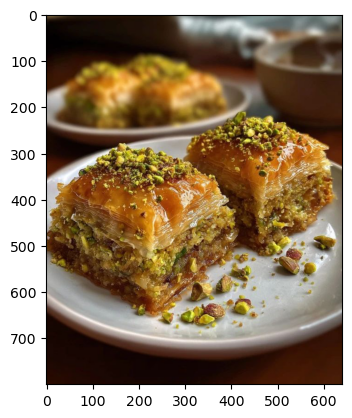

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step
The prediction is:  baklava 

    baby_back_ribs   baklava  cheese_plate  crab_cakes  dumplings  escargots  \
0        0.281597  0.497333      0.004772    0.009984   0.000588   0.006319   

   fish_and_chips  grilled_salmon  hamburger   hot_dog  
0        0.006523        0.185463   0.007411  0.000009  


In [ ]:
# Make prediction for the image you downloaded from internet
import matplotlib.pyplot as plt
img = r"C:\Users\laksh\OneDrive\sem 1\idk\Desktop\DEEP LEARNING\ASSIGNMENT\baklava image.jpeg" # the picture you downloaded from internet, which contains a type of food in your food list
plt.imshow(plt.imread(img))
plt.show()

img_array = image_process(img)
prob_df, result = prediction(model_, img_array, food_list)
print('The prediction is: ', result, '\n\n', prob_df)

In [ ]:
# Make prediction for the image you downloaded from internet
import matplotlib.pyplot as plt
img = r"C:\Users\laksh\OneDrive\sem 1\idk\Desktop\DEEP LEARNING\ASSIGNMENT\fish and chips image.jpeg"
plt.imshow(plt.imread(img))
plt.show()

img_array = image_process(img)
prob_df, result = prediction(model_, img_array, food_list)
print('The prediction is: ', result, '\n\n', prob_df)

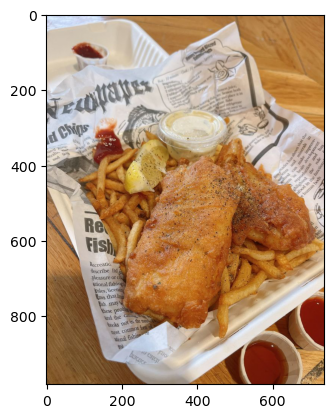

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
The prediction is:  fish_and_chips 

    baby_back_ribs   baklava  cheese_plate  crab_cakes  dumplings  escargots  \
0        0.000248  0.000401      0.000022    0.000159   0.000032   0.000005   

   fish_and_chips  grilled_salmon  hamburger   hot_dog  
0        0.998286        0.000529   0.000166  0.000152  


In [ ]:
# Make prediction for the image you downloaded from internet
import matplotlib.pyplot as plt
img = r"C:\Users\laksh\OneDrive\sem 1\idk\Desktop\DEEP LEARNING\ASSIGNMENT\fish and chips image.jpeg" # the picture you downloaded from internet, which contains a type of food in your food list
plt.imshow(plt.imread(img))
plt.show()

img_array = image_process(img)
prob_df, result = prediction(model_, img_array, food_list)
print('The prediction is: ', result, '\n\n', prob_df)

## 1.4 Report Format & Content Guidelines

OVERVIEW 
===


The objective of this assignment was to build, train, and evaluate an image classification model to distinguish between ten food categories which are baby back ribs, baklava, cheese plate, crab cakes, dumplings, escargots, fish and chips, grilled salmon, hamburger, and hot dog. This task required me to build a working classifier but also showing a way to build a model while following the universal machine learning workflow which i have done by stablishing a baseline, increasing the model's complexity until it overfits to find its threshold, and then applying regularization techniques to generalise so as to prevent the overfitting. 


For the approach, there were 4 steps that i took. First, I split the dataset of food images into training, testing, and validation in the Keras utilities that is suited to the library that is used. Secondly, multiple model variants were built and trained. I used the training and validation accuracy and loss curves as indications on whether the model was underfitting or overfitting and based on this, i would adjust the architecture or hyperparameters accordingly. Thirdly, I evaluated the trained models using a test, which did not do anything with the training and tuning process, so that i can get an accurate performance statistic. Lastly, I chose the best performing model and used it for the image classification for the pictures i chose from the internet. This allowed me to test how accurate the model is when examples not in the training set is used in real life. 

The problem needed me to build at least one model that uses a pre-trained model which is also transfer learning, together with additional models that i experimented with. I made a total 5 models that were trained and improved based off the previous models. I made a baseline Convolutional Neural Network trained from scratch, three variations of a VGG16-based transfer learning model with different regularization techniques, and for the finalised model, i fine-tuned the model by unfreezing part of the pre-trained network.

The main problem that i faced was to find the balance between the model's capacity and the limited dataset size of 750 images per class for training. The model that includes a baseline CNN with no regularization had memorized the training data while the generalization was done poorly. I then used a frozen VGG16 network as a feature extractor. I saw that it generalized much better, although i need to experiment several times to find the right strength of regularization as i know that if the L2 penalty is too strong, it would prevent the model from learning anything while if the L2 penalty is too weak, it can cause overfitting. Eventually, i figured that the best result was achieved by combining transfer learning with selective fine-tuning of the pre-trained network's deep layers, data augmentation, and a experimented value of both the L2 regularization and dropout. 

DATA PREPROCESSING AND DATA LOADING
===                                              

The food image dataset was split into train, validation, and test sets by using a preprocessing code that was provided by the school. For each of the ten assigned food classes, the first 750 images were copied into the train file, with the next 200 images going into the validation file, and 500 test images across all the classes. This step was done initially before any model development so that there is a fixed number of images used for training, validation, and testing.
In the main problem 1 notebook, the images were loaded using Keras's image_dataset_from_directory utility, which reads images directly from the files that were created during the preprocessing step. All the images were resized to 150 by 150 pixels and a batch size of 20 was used for all three data splits.
Due to the fact that the images are loaded with their original 0-255 pixel value integer range, i made sure to do rescaling. However, instead of rescaling the data initially, a Rescaling(1./255) layer was placed as the first payer inside each model architecture. This was done so that it was easier for me to look back and know exactly what i did for each model with the detailed steps. It was also so that the normalization logic was grouped up with the model itself so that any errors in the code on a new image later does not need to remeber to menually rescale the pixel values before making a prediction. I did this because i faced an issue related to this.
Class labels were one-hot encoded using label='categorical' which is appropriate as the model needs to predict the category of the images and it also works with the categorical crossentropy loss function that was used to train every model variants. The test data was loaded with shuffle = False, ensuring that the order of the predicted labels remains aligned with the order of the true labels and file order when computing evaluation metrics which is important for any per-class analysis done of the test set.

DEVELOP THE IMAGE CLASSFICATION MODELS
===

MODEL 1 -- BASELINE CNN

The first model was a basic Convolutional Neural Network built without any pre-trained components, which follows the baseline in the universal ML workflow. It consists of three convolutional blocks with 32, 64, 128 filters and each followed by max pooling, a flattening layer, a single dense(64) layer, and a final dense(10) layer with a softmax output. No dropout or weight regularization was applied. The training accuracy reached 94.92% while the validation accuracy plateaued and then declined to 35.15% with the validation loss increasing sharply from around 2.0 to 4.79 over the same period. This shows that the model was overfitting as there wasnt anything to prevent overfitting from happening, causing the model to start memorizing instead of generalising. Since there was only 750 training images per class, the model learnt the specific training examples. This result shows that a larger dataset, hypertuning, stronger regularization, or transfer learning is needed. 

MODEL 2 -- FROZEN VGG16 WITH HEAVY L2 REGULARIZATION

In order to improve the overfitting problem i faced in model 1, i replaced the convolutional layers with VGG16 which is a pre trained network. A classifier head consisting of Dense(256) with an L2 kernel regularizer with the strength of 0.01, a dropout of 0.5, and a final dense layer Dense(10) with a softmax layer was trained on top of the frozen VGG16 features for 20 epochs. However, the model started showing signs of underfitting rather than overfitting as both the training and validation accuracy plateaued together in the 45-53% range, with training accuracy never increasing much higher than the validation accuracy. This was an indication that the L2 penalty of 0.01 was too aggressive, constraining the classifier head's weights so heavily that it could not properly fit even the training data. This was an important discovery as it showed that having to high of a regularizer value is as much a risk as overfitting, and that the correct regularization strength had to be tuned based on the architecture and dataset.

MODEL 3 -- FROZEN VGG16 WITH ONLY DROPOUT

Due to the discovery that the L2 regularizer was penalising the weights too harshly, the L2 regularizer was removed entirely. This left only Dropout(0.5) in the frozen VGG16 architecture and i trained it for 15 epochs. This time, the training accuracy increased steadily to 78.17% while validation accuracy plateaued around 58-60%, which had a training-validation gap of roughly 20 percentage points. This shows that overfitting had happened again, although the performance of the model is definitely higher than model 1's baseline performance. This result showed that the dropout alone was not enough to fully control the overfitting once the L2 regularizer was removed and that the frozen VGG16 features placed a practical ceiling on how well a simple classifier head could perform, since the convolutional base itself was not being allowed to adapt to the specific characteristics of the images of food.

MODEL 4 AND 5 -- FINE-TUNING VGG16 WITH AUGEMENTATION

In the final stage of developement, i addressed the remaining issues, the performance ceiling imposed by VGG16 features and the overfitting being reintroduced once regularization was adjusted to not be as strong, simultaneously. The VGG16 convolutional base was partially unfrozen which allowed the weights in the last convolutional block to be updated during training while the earlier blocks remained frozen in order to preserve their already learned weights. I also added a data augmentation pipeline, that included a RandomFlip, RandomRotation, and RandomZoom. This pipeline was added before the convolutional base which allowed the model to have much more variety of data to use to train on as the images are the same but was just visually transformed into different ways so that the model can train on them without additional data. A mild L2 regularizer(0.0001) was added, which is significantly weaker than the one used in model 2. This regularizer was added on the Dense(256) classifier layer, and the Adam optimizer was used with a small learning rate of 1e-5, since fine-tuning pre-trained weights requires much more gentler updates in comparison to training a randomly initialized classifier head from scratch.  A larger learning rate can potentially ruin the useful features of the VGG16.
I made two variants of this model where they were both fine tuned, trained and compared with each other. In model 4, I used a Dropout(0.3) and trained for a full 30 epochs, and reached a final training accuracy of 69.09% and a validation accuracy of 63.40%. The difference between the two accuracies are around 6 percentage points. This shows that the model is able to generalize well even though the accuracy is still not as high as wanted. In order to increase the accuracy, I did some changes to model 5. In model 5, i used a stronger Dropout(0.5) and trained it for only 20 epochs with an EarlyStopping callback. The model accuracy for model 5 was 77.67% for the training accuracy and 71.10% for the validation accuracy. Among the 5 models, model 5 showed the best results. Even though the training-validation accuracy gap is 6.6 percentage points which is slightly more than model 4 but similar, it still showed a much higher validation accuracy with it being about 8 percentage points higher than model 4 and 12 points above model 3.

Across all the models that i have been fine-tuning, quite a few hyperparameters were tuned repeatedly based on the results of the model’s performance. I decreased the strength of the L2 penalty from 0.01 to 0.0001 after model 2 showed that the strong L2 penalty caused over-regularization, I increased the dropout rate from 0.3 to 0.5 between model 4 and 5 so that i can use the full capacity after i had unfreezed block5, changed from RMSprop to Adam with a low learning rate of 1e-5, and the use of EarlyStopping to avoid wasting time but running all the epochs even though the validation loss stopped improving.

Evaluate Tuned Model Using Test Images
===

Both Model 1 and Model 5 were evaluated using the 500 images that were held out in the test set. These 500 images have not been used during neither training and model selection. Model 1 had a test accuracy of only 34.40% with a high test loss of 4.9159. A huge indicator of overfitting was observed in the validation curves and it showed that strong training performance does not mean that the model is able to classify unseen food images well.                                                               Model 5 however had a test accuracy of 72.80% with a test loss of 0.9283 and its validation performance from training of 71.10% accuracy with a 0.9071 loss. The small difference between validation and test metrics of around 1.7 percentage points in accuracy, indicates that the model's validation performance during training was a good estimate of how it woould perform on entirely new data. The results of Model 5 especially the validation results, shows a clear difference in the model's performance compared to the other models that i have built. Hence, this supports why i chose model 5 as the best performing model produced in this assignment.
To understand the results better, i made a confusion matrix and per-class classification report on the test set. Based on the results, i could tell that the performance among the ten categories were not the same: cheese_plate (84% recall, 0.81 F1), hot_dog (89% precision, 0.83 F1) and escargots (78% recall, 0.80 F1) were able to be classified well by the model, while the model was able to achieve a high precision of  95% despite a lower recall of 70%, which means that the model rarely mislabelled other foods as dumplings but would often miss actual images of dumplings, meaning that it misclassifies them across multiple categories rather than mistakenly classifying them as a particular other category. At the other end, grilled_salmon (52% recall, 0.57 F1) and crab_cakes (56% recall, 0.58 F1) were the weakest-performing classes, with the F1 avergaing at 0.73 which is close to the average of 0.73, indicating that the errors were reasonably spread across classes rather than concentrated in a small number of severely under-performing categories.

Class	        Precision	Recall	F1-score	Support
baby_back_ribs	0.63	    0.78	0.70	    50
baklava	        0.75	    0.78	0.76	    50
cheese_plate	0.78	    0.84	0.81	    50
crab_cakes	    0.61	    0.56	0.58	    50
dumplings	    0.95	    0.70	0.80	    50
escargots	    0.81	    0.78	0.80	    50
fish_and_chips	0.71	    0.80	0.75	    50
grilled_salmon	0.62	    0.52	0.57	    50
hamburger	    0.63	    0.74	0.68	    50
hot_dog	        0.89	    0.78	0.83	    50

The confusion matrix reveals a pattern behind the weakest classes which are grilled_salmon and crab_cakes. The pattern is that they were most confused with each other and with baby_back_ribs, with 7 grilled_salmon test images being misclassified as crab_cakes and a further 4 misclassified as baby_back_ribs. All three of these categories do have similarities in terms of their visuals meaning that they share similar colours and the way they are displayed, which might make it harder for the model to seperate them using colour or their arrangment alone at a 150 by 150 resolution. This result is similar to the one i found in step 4 where the charcuterie board image was misclassified as grilled_salmon, which is the same confusion direction here. This match between the test results and the single-image prediction confirms it's a consistent weakness of the model, not a one-off mistake, and points to platter-style, protein-heavy dishes as the clearest target for improvement.


Use the Model to Perform Classification 
===

In order to find out how the model works when i use outside images, three food images were downloaded from pinterest. I then loaded the image and it was resized to match the model's expected 150 by 150 input using Keras's image loading utilities, converted to a numeric array and reshaped before being passed to the model's predict function. To add on, the image was not manually rescaled before being passed to the model since the model's built in Rescaling layer already does this automatically. In the earlier version of the code, the code divided the pixel values by 255 twice, once manually and once again inside the model. As a result, every prediction came of the same regardless of which image was used. Fixing this double rescaling was very important as it helped the model to produce much more accurate predictions.

Image	          Predicted Class	Confidence	Correct?
Cheese_plate	  grilled_salmon	70.18%	    No
Baklava photo	  baklava	        49.73%	    Yes
Fish and chips 	  fish_and_chips	99.83%	    Yes

Two out of the three predictions were correct. An image of fish and chips were classified correctly with a very high confidence of 99.83% which shows that the mode has learned to identify the class well by learning distinctive features. A baklava photograph was also classified correctly although it has a much lower confidence of 49.73%. The model had a 28.16% probability to baby_back_ribs and 18.55% to grilled_salmon, suggesting that the specific baklava image used may have similar visual characteristics to the grilled_salmon, even though the correct class ultimately had the highest score.

The one incorrect prediction was the charcuterie board image, which was supposed to represent the cheese_plate class. The model had incorrectly classified the charcuterie board image as grilled_salmon instead with a 70.18% confidence while the actual correct class ranked third with only 9.92% and the second ranked being baby_back_ribs at 16.68%. A possibility as to why the model predicts grilled_salmon might be because a charcuterie board tends to not only have cheese but other food items along with it and the brown and orange colours may have resembeled grilled salmon or baby back ribs. Since charcuterie boards are a platter, the model might have found it much harder to identify the food class as there are multiple food on one plate which can cause classification to be harder.

Summary
===

In summary, in this assignment, I followed a full step-by-step process of building and improving the models until i get the best performing model for classifying food images into ten categories. There is a totoal of 5 different versions of the model.

Model 1 was a basic CNN built and trained completely from scratch. It however overfitted badly meaning it memorized the patterns of the training data and could not perform well on new data meaning that it could not generalize well. It only reached 34.40% accuracy on the test set.

Model 2 used VGG16, which is a pre-trained model through transfer learning, and its layers are frozen so they  cannot be updated during training. This version also used a very strong L2 penalty which is a technique and this helps to make sure the model does not rely too heavily on any single feature. However the penalty was too strong so instead of overfitting, the model started underfitting as it was too limited to learn the patterns well hence the accuracy stayed stuck around 45-50%.

Model 3 removed the strong L2 penalty and instead brought back the overfitting problem, but the model still performed better overall, reaching roughly 58-60% validation accuracy. This showed that even without adjusting VGG16's internal layers, the pre-trained features were genuinely useful.

Models 4 and 5 combined several techniques together: partially unfreezing and fine-tuning the last convolutional block of VGG16, adding data augmentation, using a much lighter L2 penalty, and adding dropout. This combination worked well as Model 5, the final version, reached 72.80% accuracy on the test set, and its validation and test results were very close to each other. This means the model's performance was consistent and trustworthy. This was the best and most dependable result in the whole project.

Overall, these results show two important things: transfer learning is genuinely valuable for small, specialized image datasets like this one, and successfully training a model requires carefully balancing how much the model is allowed to learn against how strongly it is restricted from overfitting, at every stage of development.